# Milestone Two figures

This notebook rebuilds every figure in my Milestone Two report from the three capstone CSVs, using the same splits, seeds, and settings as the weekly notebooks (Weeks 8-11). Each figure is saved to `figures/` and shown inline. Numbers in the printed output and in the plots match the weekly notebooks.

In [1]:
import os, numpy as np, pandas as pd, matplotlib, warnings, json
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, silhouette_score, adjusted_rand_score
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram

D = ""; OUT = "figures/"; os.makedirs(OUT, exist_ok=True)
BLUE, ORANGE, GREEN, PURPLE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#1b9e77", "#7b4fb8", "#c9c8c3", "#2b2b2b", "#6b6a66"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.6, "legend.frameon": False,
                     "lines.linewidth": 2, "savefig.dpi": 300, "savefig.bbox": "tight"})
cv5 = StratifiedKFold(5, shuffle=True, random_state=42)
stats = {}

df = pd.read_csv(D + "ecommerce_data.csv")
X = pd.get_dummies(df[["Sales", "Quantity", "Discount", "Segment", "Region", "Ship Mode", "Category", "Sub-Category"]],
                   columns=["Segment", "Region", "Ship Mode", "Category", "Sub-Category"], drop_first=True).astype(float)
y = (df.Profit > 0).astype(int).values

**Figure 1 (Week 8, KNN).** Recomputes the best five-fold CV AUC for each Minkowski *p* (tuning *k* over the Week 8 grid) with all 29 features and with the 3 numeric features, and the test F1 on unprofitable orders for unscaled vs. standardized KNN at *k* = 5.

CV AUC, all 29 features: [np.float64(0.951), np.float64(0.947), np.float64(0.946), np.float64(0.944), np.float64(0.94), np.float64(0.932), np.float64(0.924)]
CV AUC, 3 numeric:       [np.float64(0.952), np.float64(0.953), np.float64(0.953), np.float64(0.953), np.float64(0.953), np.float64(0.952), np.float64(0.951)]
test F1 (unscaled, standardized): [0.441, 0.756]


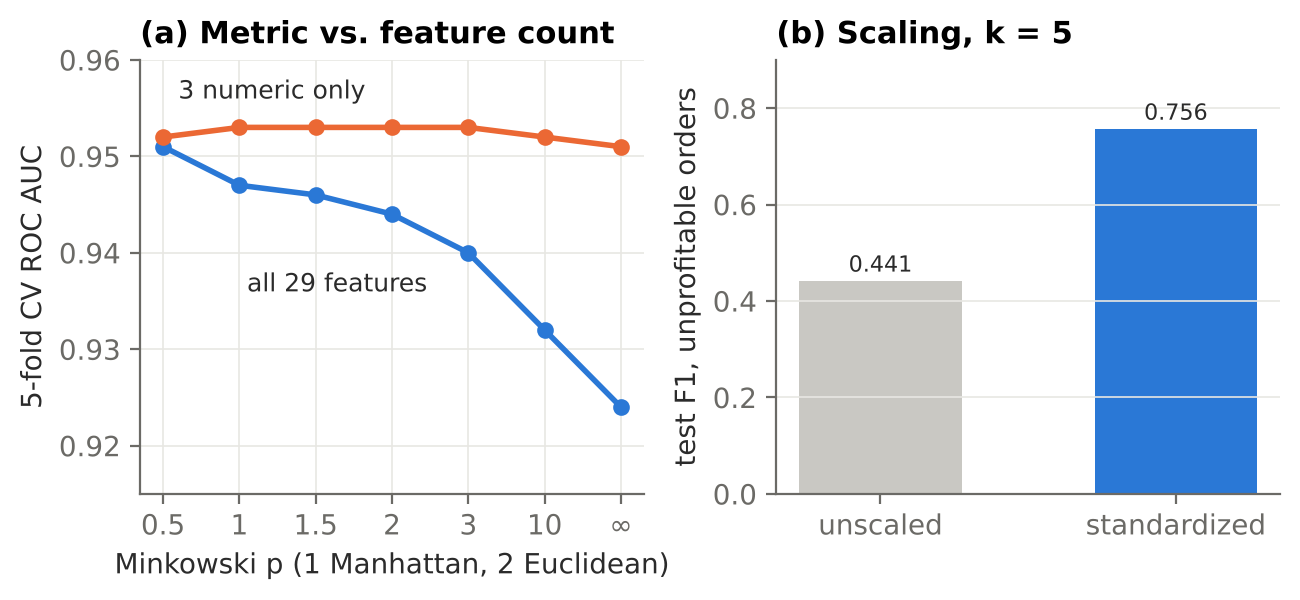

In [2]:
from scipy.spatial.distance import cdist
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score
# recompute the Week 8 numbers: same split, scaler fit on training data only
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
sc = StandardScaler().fit(Xtr); Str, Ste = sc.transform(Xtr), sc.transform(Xte)
num_idx = [list(X.columns).index(c) for c in ["Sales", "Quantity", "Discount"]]
pvals = [0.5, 1, 1.5, 2, 3, 10, np.inf]; k_grid = [1, 3, 5, 9, 15, 25, 41]
def best_cv_auc(A, p):
    Dm = cdist(A, A, metric="chebyshev") if np.isinf(p) else cdist(A, A, metric="minkowski", p=p)
    return max(cross_val_score(KNeighborsClassifier(n_neighbors=k, metric="precomputed"), Dm, ytr, cv=cv5, scoring="roc_auc").mean() for k in k_grid)
all29 = [round(best_cv_auc(Str, p), 3) for p in pvals]
num3 = [round(best_cv_auc(Str[:, num_idx], p), 3) for p in pvals]
f1_scaling = [round(f1_score(yte, KNeighborsClassifier(5).fit(A, ytr).predict(B), pos_label=0), 3) for A, B in [(Xtr.values, Xte.values), (Str, Ste)]]
print("CV AUC, all 29 features:", all29); print("CV AUC, 3 numeric:      ", num3); print("test F1 (unscaled, standardized):", f1_scaling)
ps = ["0.5", "1", "1.5", "2", "3", "10", "∞"]
fig, ax = plt.subplots(1, 2, figsize=(6.6, 3.1))
ax[0].plot(ps, all29, "-o", color=BLUE, ms=5); ax[0].plot(ps, num3, "-o", color=ORANGE, ms=5)
ax[0].text(1.1, 0.936, "all 29 features", color=INK, fontsize=9); ax[0].text(0.2, 0.956, "3 numeric only", color=INK, fontsize=9)
ax[0].set_xlim(-0.3, 6.3); ax[0].set_ylim(0.915, 0.96); ax[0].set_xlabel("Minkowski p (1 Manhattan, 2 Euclidean)"); ax[0].set_ylabel("5-fold CV ROC AUC")
ax[0].set_title("(a) Metric vs. feature count")
b = ax[1].bar(["unscaled", "standardized"], f1_scaling, color=[GREY, BLUE], width=0.55)
for r, v in zip(b, f1_scaling): ax[1].text(r.get_x() + r.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center", fontsize=8, color=INK)
ax[1].set_ylim(0, 0.9); ax[1].set_ylabel("test F1, unprofitable orders"); ax[1].set_title("(b) Scaling, k = 5"); ax[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(OUT + "fig1.png"); plt.show()

**Figure 2 (Week 9, gradient boosting).** E-commerce validation AUC as trees are added for four learning rates, and Instacart training vs. validation AUC at learning rates 0.3 and 0.05. The depth results are printed (they are reported in the text, not plotted).

learning rate -> (best n_trees, best val AUC, val AUC at 600): {1.0: (4, 0.97, 0.951), 0.3: (173, 0.981, 0.977), 0.1: (572, 0.981, 0.981), 0.03: (439, 0.98, 0.98)}
depth -> (train AUC, CV AUC): {1: (0.983, np.float64(0.979)), 2: (0.991, np.float64(0.978)), 3: (0.999, np.float64(0.976)), 4: (1.0, np.float64(0.974)), 6: (1.0, np.float64(0.971)), 8: (1.0, np.float64(0.968))}


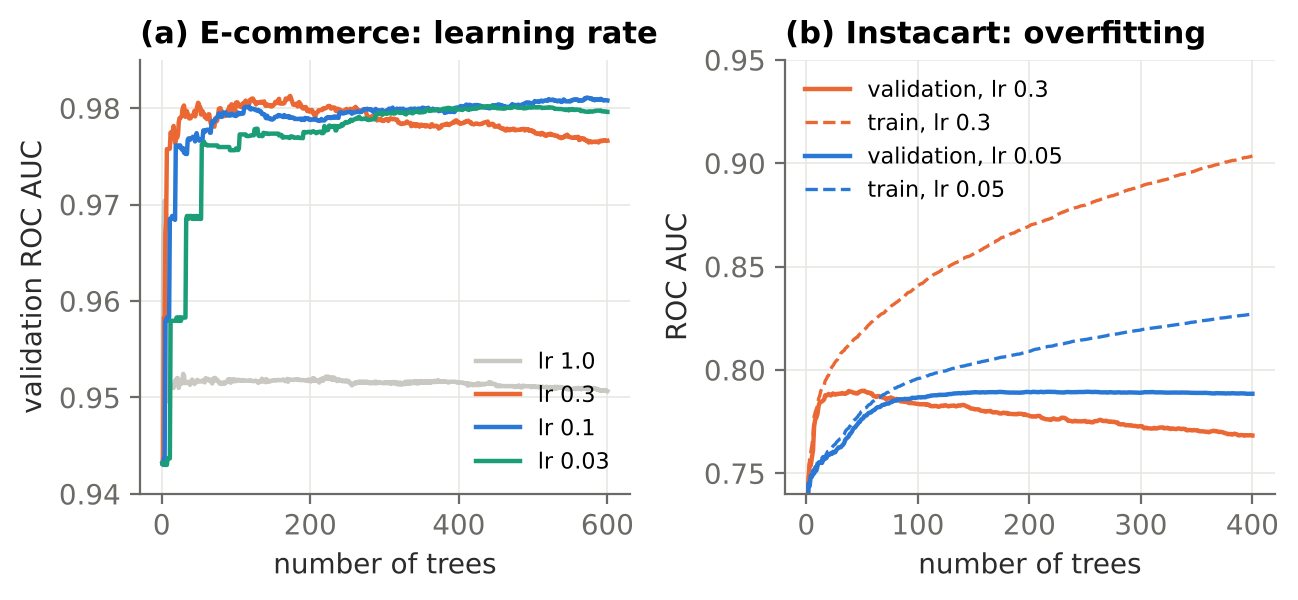

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)
curves = {}
for lr in [1.0, 0.3, 0.1, 0.03]:
    g = GradientBoostingClassifier(n_estimators=600, learning_rate=lr, max_depth=2, random_state=42).fit(X_fit, y_fit)
    curves[lr] = [roc_auc_score(y_val, p[:, 1]) for p in g.staged_predict_proba(X_val)]
stats["lr_best"] = {lr: (int(np.argmax(c)) + 1, round(max(c), 3), round(c[-1], 3)) for lr, c in curves.items()}
depth = {}
for d in [1, 2, 3, 4, 6, 8]:
    g = GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=d, random_state=42)
    depth[d] = (roc_auc_score(y_train, g.fit(X_train, y_train).predict_proba(X_train)[:, 1]), cross_val_score(g, X_train, y_train, cv=cv5, scoring="roc_auc").mean())
stats["depth"] = {d: (round(a, 3), round(b, 3)) for d, (a, b) in depth.items()}
print("learning rate -> (best n_trees, best val AUC, val AUC at 600):", stats["lr_best"])
print("depth -> (train AUC, CV AUC):", stats["depth"])
ins = pd.read_csv(D + "insta_df_sample.csv")
ins["days_since_prior"] = ins["days_since_prior_order"].fillna(-1)
ins["aisle_code"] = ins["aisle"].astype("category").cat.codes; ins["dept_code"] = ins["department"].astype("category").cat.codes
f7 = ["order_number", "order_dow", "order_hour_of_day", "add_to_cart_order", "days_since_prior", "aisle_code", "dept_code"]
Xi_tr, _, yi_tr, _ = train_test_split(ins[f7], ins.reordered.values, test_size=0.25, random_state=42, stratify=ins.reordered)
Xi_fit, Xi_val, yi_fit, yi_val = train_test_split(Xi_tr, yi_tr, test_size=0.25, random_state=42, stratify=yi_tr)
ic = {}
for lr in [0.3, 0.05]:
    g = GradientBoostingClassifier(n_estimators=400, learning_rate=lr, max_depth=3, random_state=42).fit(Xi_fit, yi_fit)
    ic[lr] = ([roc_auc_score(yi_fit, p[:, 1]) for p in g.staged_predict_proba(Xi_fit)], [roc_auc_score(yi_val, p[:, 1]) for p in g.staged_predict_proba(Xi_val)])
stats["insta"] = {lr: (int(np.argmax(v)) + 1, round(max(v), 3), round(v[-1], 3), round(t[-1], 3)) for lr, (t, v) in ic.items()}

fig, ax = plt.subplots(1, 2, figsize=(6.6, 3.1))
for lr, c in zip([1.0, 0.3, 0.1, 0.03], [GREY, ORANGE, BLUE, GREEN]):
    ax[0].plot(range(1, 601), curves[lr], color=c, lw=1.6, label=f"lr {lr}")
ax[0].set_ylim(0.94, 0.985); ax[0].set_xlabel("number of trees"); ax[0].set_ylabel("validation ROC AUC"); ax[0].set_title("(a) E-commerce: learning rate"); ax[0].legend(fontsize=8, loc="lower right")
for lr, c in [(0.3, ORANGE), (0.05, BLUE)]:
    ax[1].plot(range(1, 401), ic[lr][1], color=c, lw=1.6, label=f"validation, lr {lr}"); ax[1].plot(range(1, 401), ic[lr][0], color=c, lw=1.2, ls="--", label=f"train, lr {lr}")
ax[1].set_xlabel("number of trees"); ax[1].set_ylabel("ROC AUC"); ax[1].set_title("(b) Instacart: overfitting"); ax[1].legend(fontsize=8, loc="upper left"); ax[1].set_ylim(0.74, 0.95)
plt.tight_layout(); plt.savefig(OUT + "fig2.png"); plt.show()

**Figure 3 (Week 10, K-Means).** Silhouette score and seed stability (ARI) by *k*, and the *k* = 4 clusters. Profit is used only to label the legend.

silhouette by k: {2: np.float64(0.284), 3: np.float64(0.345), 4: np.float64(0.35), 5: np.float64(0.332), 6: np.float64(0.326), 7: np.float64(0.315), 8: np.float64(0.317), 9: np.float64(0.316), 10: np.float64(0.315)}
seed stability (ARI) by k: {2: np.float64(0.093), 3: np.float64(0.779), 4: np.float64(0.999), 5: np.float64(0.897), 6: np.float64(0.652)}


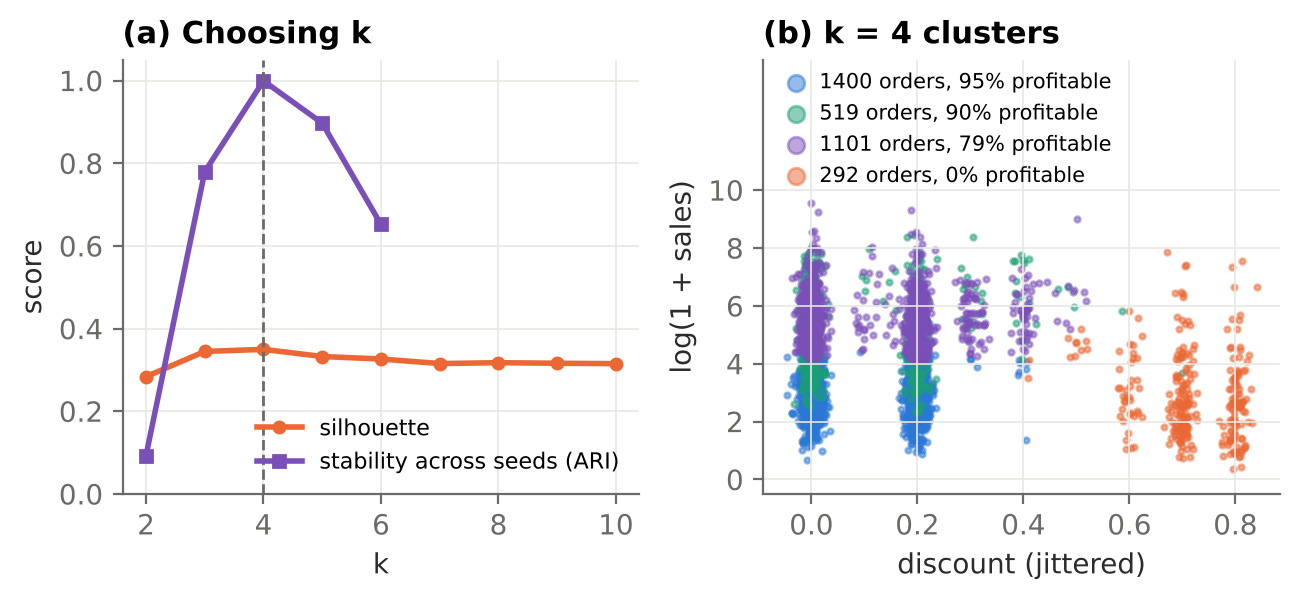

In [4]:
A = StandardScaler().fit_transform(pd.DataFrame({"s": np.log1p(df.Sales), "q": df.Quantity, "d": df.Discount}))
ks = list(range(2, 11)); inert, sil = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=42).fit(A); inert.append(km.inertia_); sil.append(silhouette_score(A, km.labels_))
seed_ari = [np.mean([adjusted_rand_score(KMeans(k, n_init=1, random_state=0).fit_predict(A), KMeans(k, n_init=1, random_state=s).fit_predict(A)) for s in range(1, 11)]) for k in range(2, 7)]
stats["kmeans"] = {"sil": dict(zip(ks, np.round(sil, 3))), "seed_ari": dict(zip(range(2, 7), np.round(seed_ari, 3)))}
print("silhouette by k:", stats["kmeans"]["sil"]); print("seed stability (ARI) by k:", stats["kmeans"]["seed_ari"])
lab4 = KMeans(4, n_init=10, random_state=42).fit_predict(A)
fig, ax = plt.subplots(1, 2, figsize=(6.6, 3.1))
ax[0].set_xticks(range(2, 11, 2))
ax[0].plot(ks, sil, "-o", color=ORANGE, ms=4, label="silhouette"); ax[0].plot(range(2, 7), seed_ari, "-s", color=PURPLE, ms=4, label="stability across seeds (ARI)")
ax[0].axvline(4, color=MUTED, ls="--", lw=1); ax[0].set_xlabel("k"); ax[0].set_ylabel("score"); ax[0].set_title("(a) Choosing k"); ax[0].legend(fontsize=8, loc="lower right"); ax[0].set_ylim(0, 1.05)
order = pd.Series(df.Discount.values).groupby(lab4).mean().sort_values().index
cols = [BLUE, GREEN, PURPLE, ORANGE]
for c, col in zip(order, cols):
    m = lab4 == c
    ax[1].scatter(df.Discount[m] + np.random.default_rng(c).normal(0, 0.012, m.sum()), np.log1p(df.Sales[m]), s=4, alpha=0.5, color=col,
                  label=f"{m.sum()} orders, {y[m].mean():.0%} profitable", rasterized=True)
ax[1].set_xlabel("discount (jittered)"); ax[1].set_ylabel("log(1 + sales)"); ax[1].set_title("(b) k = 4 clusters"); ax[1].set_ylim(-0.5, 14.5); ax[1].set_yticks(range(0, 11, 2))
ax[1].legend(fontsize=7.5, markerscale=3, loc="upper left", ncol=1, handletextpad=0.1, borderaxespad=0.2)
plt.tight_layout(); plt.savefig(OUT + "fig3.png"); plt.show()

**Figure 4 (Week 11, DBSCAN).** The k-distance plot used to choose `eps`, and the DBSCAN clusters and noise at `eps` = 0.5, `min_samples` = 10.

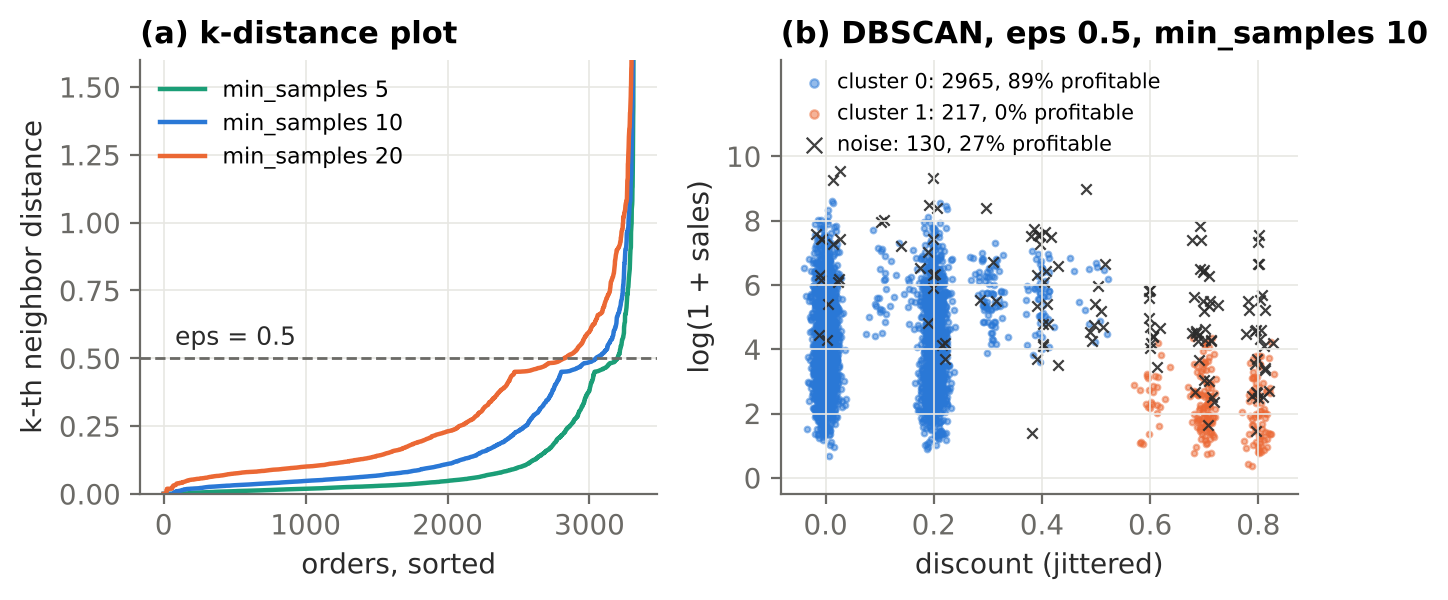

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(6.6, 3.1))
for ms, c in [(5, GREEN), (10, BLUE), (20, ORANGE)]:
    dk = np.sort(NearestNeighbors(n_neighbors=ms).fit(A).kneighbors(A)[0][:, -1]); ax[0].plot(dk, color=c, lw=1.6, label=f"min_samples {ms}")
ax[0].axhline(0.5, color=MUTED, ls="--", lw=1); ax[0].text(80, 0.55, "eps = 0.5", fontsize=9, color=INK)
ax[0].set_ylim(0, 1.6); ax[0].set_xlabel("orders, sorted"); ax[0].set_ylabel("k-th neighbor distance"); ax[0].set_title("(a) k-distance plot"); ax[0].legend(fontsize=8, loc="upper left")
lab = DBSCAN(eps=0.5, min_samples=10).fit_predict(A)
for c, col, nm in [(0, BLUE, "cluster 0"), (1, ORANGE, "cluster 1"), (-1, INK, "noise")]:
    m = lab == c
    ax[1].scatter(df.Discount[m] + np.random.default_rng(c + 5).normal(0, 0.012, m.sum()), np.log1p(df.Sales[m]), s=4 if c >= 0 else 14, marker="o" if c >= 0 else "x",
                  lw=0.8, alpha=0.5 if c >= 0 else 0.9, color=col, label=f"{nm}: {m.sum()}, {y[m].mean():.0%} profitable", rasterized=True)
ax[1].set_xlabel("discount (jittered)"); ax[1].set_ylabel("log(1 + sales)"); ax[1].set_title("(b) DBSCAN, eps 0.5, min_samples 10")
ax[1].set_yticks(range(0, 11, 2)); ax[1].set_ylim(-0.5, 13); ax[1].legend(fontsize=7.5, markerscale=1.5, loc="upper left", handletextpad=0.1, borderaxespad=0.2)
plt.tight_layout(); plt.savefig(OUT + "fig4.png"); plt.show()

**Figure 5 (Week 11, hierarchical clustering).** The last 16 merges of the Ward and single-linkage dendrograms.

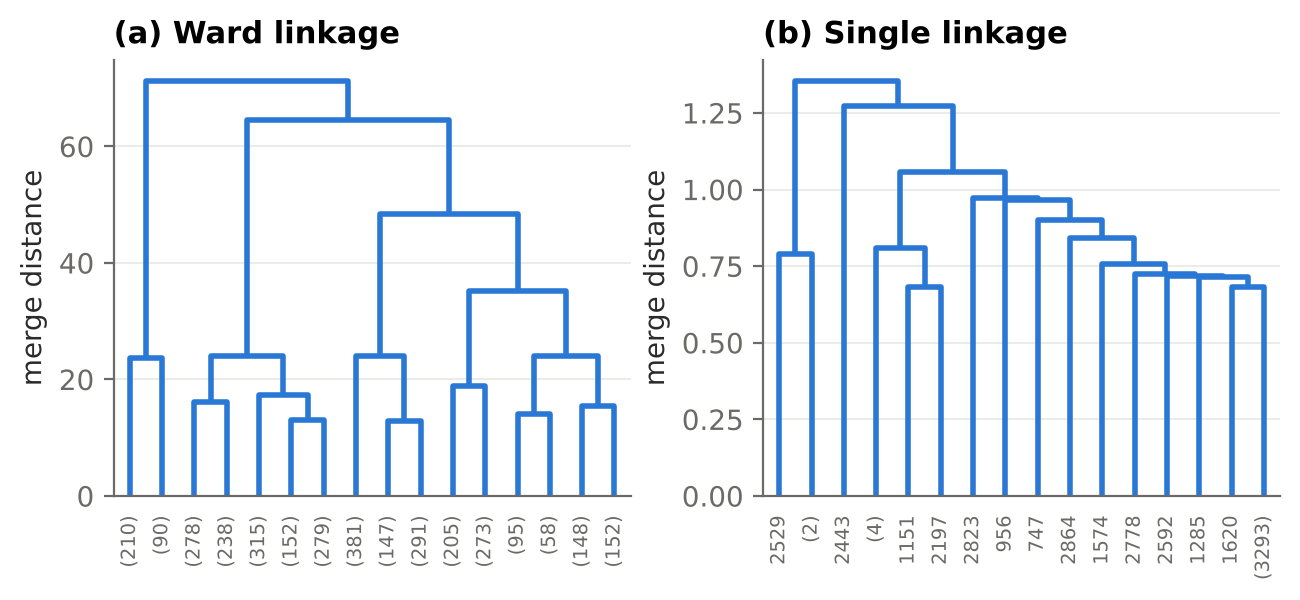

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(6.6, 3.1))
for a, m, t in [(ax[0], "ward", "(a) Ward linkage"), (ax[1], "single", "(b) Single linkage")]:
    Z = linkage(A, m)
    dendrogram(Z, truncate_mode="lastp", p=16, ax=a, color_threshold=0, above_threshold_color=BLUE, leaf_font_size=7, leaf_rotation=90)
    a.set_title(t); a.set_ylabel("merge distance"); a.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(OUT + "fig5.png"); plt.show()